# 03 — Modelling, and the decision that actually matters

**Question this notebook answers:** given that almost any classifier scores ~97% on this
dataset, what is left to decide?

The answer is the threshold. This notebook establishes that model choice is close to
irrelevant here, and that the consequential decision — the one that changes how many
cancers get missed — is one that most published versions of this project never make
explicitly.

Read `wdbc.names` and the problem is framed for you: the original authors state the
classes are **linearly separable on all 30 features**, and report **97.5% accuracy using
just three of them** (worst area, worst smoothness, mean texture) under repeated 10-fold
cross-validation, in 1993. Any modern model reporting ~97% has matched a thirty-year-old
linear-programming decision tree. That is the benchmark, and beating it is not where the
value is.

In [1]:
import sys, warnings, json
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

from src import data as D
from src import evaluation as E
from src import figures as F
from src import models as M

pd.set_option("display.width", 170, "display.max_columns", 40)

X_train, X_test, y_train, y_test = D.split()
features = list(X_train.columns)
print(f"train {len(X_train)} patients ({y_train.sum()} malignant)")
print(f"test  {len(X_test)} patients ({y_test.sum()} malignant)  <- untouched until the final section")

train 455 patients (170 malignant)
test  114 patients (42 malignant)  <- untouched until the final section


## Protocol

Three choices, each of which would materially change the reported numbers if made
differently.

**A held-out test set of 114 patients, touched once.** Defined in `src/data.py` and
imported everywhere, so "the test set was used once" is enforced by the code rather than
promised in prose. It is stratified, because at n=114 an unstratified draw could shift
the malignant share by several points.

**10-fold cross-validation repeated 10 times for model selection.** Repetition is not
decoration. With 455 training rows, a single 10-fold estimate has enough fold-to-fold
variance that models separated by half a point of accuracy cannot be distinguished. The
standard deviations reported below are the reason this notebook concludes what it does.

**Scaling inside the pipeline, never outside it.** Fitting a scaler on the full training
matrix before cross-validating lets every training fold see the mean and variance of its
own validation fold. On a dataset this separable the resulting leak is small — which is
what makes it dangerous, because it inflates precisely the number being reported.
`tests/test_pipeline_integrity.py` pins this.

## Do different models disagree?

Nine classifiers spanning the assumption space: linear boundaries, a non-linear
boundary, a local method, an independence assumption, and two tree ensembles. Plus a
majority-class baseline, because 62.6% accuracy is free.

In [2]:
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=42)
scoring = ["roc_auc", "recall", "precision", "accuracy", "neg_brier_score"]

rows = []
for name, estimator in M.candidates().items():
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "model": name,
        "roc_auc": scores["test_roc_auc"].mean(),
        "roc_auc_sd": scores["test_roc_auc"].std(),
        "recall": scores["test_recall"].mean(),
        "recall_sd": scores["test_recall"].std(),
        "precision": scores["test_precision"].mean(),
        "accuracy": scores["test_accuracy"].mean(),
        "brier": -scores["test_neg_brier_score"].mean(),
    })
comparison = pd.DataFrame(rows).sort_values("roc_auc", ascending=False)
comparison.round(4)

,model,roc_auc,roc_auc_sd,recall,recall_sd,precision,accuracy,brier
1,logistic regression (L2),0.9942,0.0112,0.9506,0.0575,0.9765,0.9725,0.0210
4,SVM (RBF),0.9940,0.0104,0.9500,0.0548,0.9773,0.9727,0.0232
2,logistic regression (L1),0.9931,0.0153,0.9459,0.0626,0.9780,0.9714,0.0218
5,SVM (linear),0.9921,0.0147,0.9394,0.0625,0.9717,0.9666,0.0253
3,linear discriminant analysis,0.9919,0.0130,0.8782,0.0759,0.9916,0.9516,0.0382
9,gradient boosting,0.9909,0.0152,0.9335,0.0632,0.9709,0.9641,0.0310
8,random forest,0.9894,0.0153,0.9335,0.0669,0.9528,0.9569,0.0334
7,gaussian naive bayes,0.9868,0.0161,0.9012,0.0748,0.9288,0.9353,0.0600
6,k-nearest neighbours (k=5),0.9856,0.0211,0.9135,0.0683,0.9880,0.9633,0.0295
0,baseline (majority class),0.5000,0.0000,0.0000,0.0000,0.0000,0.6263,0.3737


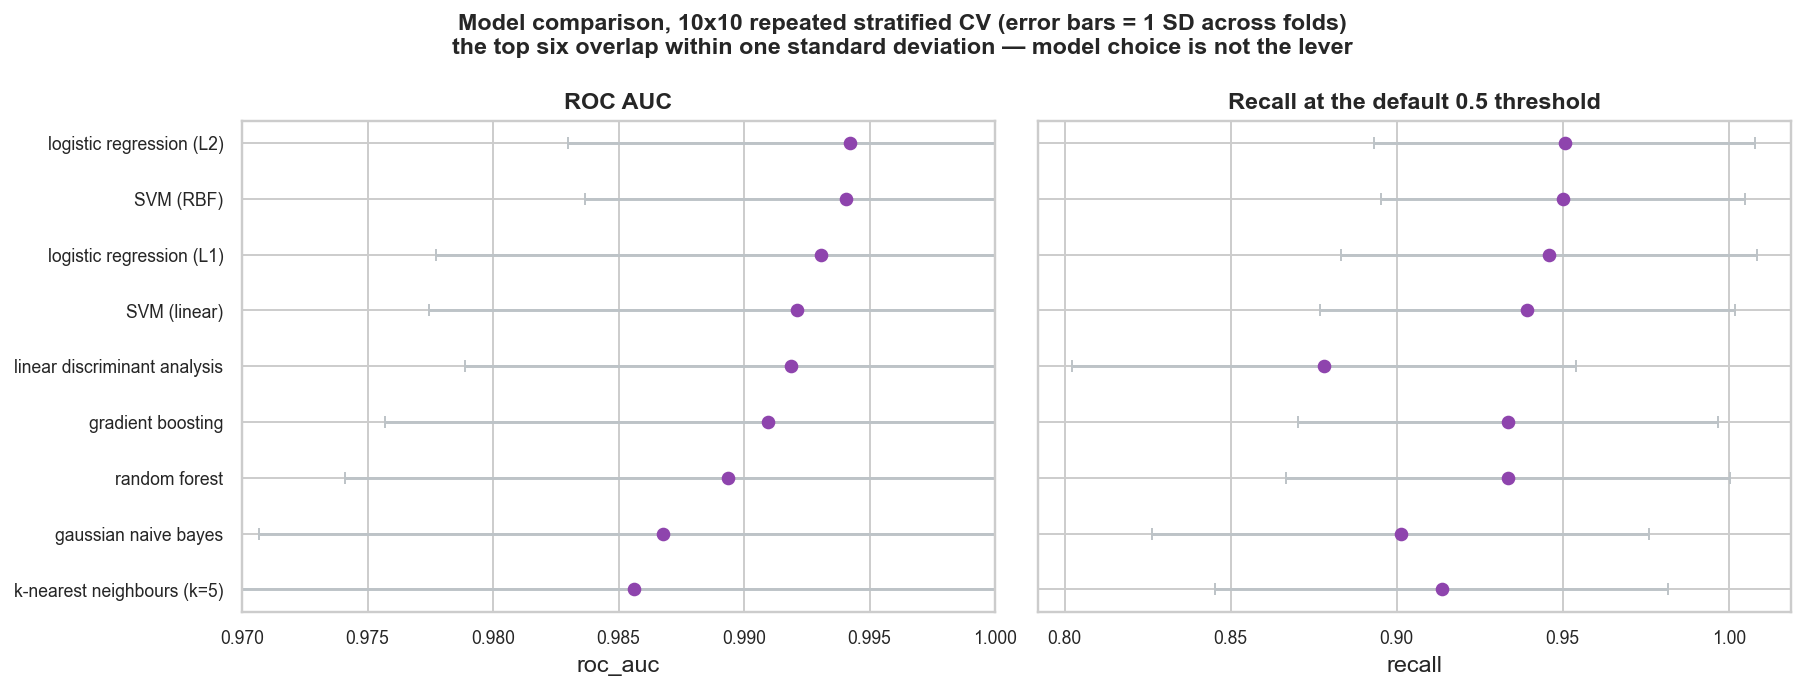

In [3]:
F.model_comparison(comparison)
Image("../outputs/figures/06_model_comparison.png")

**The top six models span 0.9921 to 0.9942 in AUC, against a fold-to-fold standard
deviation of about 0.011.** The entire spread between them is a fifth of the noise in
any one estimate. Ranking them would be reading tea leaves.

This is worth stating plainly because the conventional move here — try more models, tune
harder, report the winner — cannot produce anything real on this dataset. The problem is
close to linearly separable, as the 1993 authors said. A gradient booster and a logistic
regression agree because there is nothing left for extra flexibility to capture.

Two smaller results are genuine, though:

- **LDA's recall collapses to 0.878** while its AUC stays at 0.992. Its *ranking* is
  fine; its default threshold is badly placed, because LDA's implicit equal-covariance
  assumption is violated (malignant cases are far more dispersed). This is the first
  hint that the threshold, not the model, is where the action is.
- **The random forest is the worst-calibrated** of the strong models (Brier 0.033 vs
  0.021). It ranks patients well but its probabilities are compressed toward the middle —
  which matters, because the rest of this notebook depends on the probabilities meaning
  what they say.

### Would tuning change this?

Worth checking rather than assuming, since "we didn't tune" is a fair criticism.

In [4]:
from sklearn.linear_model import LogisticRegression
rows = []
for C in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 100.0]:
    s = cross_validate(M.pipeline(LogisticRegression(max_iter=5000, C=C, random_state=42)),
                       X_train, y_train, cv=cv, scoring=["roc_auc", "recall", "neg_brier_score"],
                       n_jobs=-1)
    rows.append({"C": C, "roc_auc": s["test_roc_auc"].mean(), "roc_auc_sd": s["test_roc_auc"].std(),
                 "recall": s["test_recall"].mean(), "brier": -s["test_neg_brier_score"].mean()})
tuning = pd.DataFrame(rows)
best, default = tuning.loc[tuning.roc_auc.idxmax()], tuning[tuning.C == 1.0].iloc[0]
print(tuning.round(5).to_string(index=False))
print(f"\nbest C = {best.C} -> AUC {best.roc_auc:.5f}   |   default C = 1.0 -> AUC {default.roc_auc:.5f}")
print(f"gain from tuning: {best.roc_auc - default.roc_auc:.5f}")
print(f"fold-to-fold SD:  {default.roc_auc_sd:.5f}   ({default.roc_auc_sd / (best.roc_auc - default.roc_auc):.0f}x larger)")

     C  roc_auc  roc_auc_sd  recall   brier
  0.01  0.99130     0.01347 0.86882 0.04570
  0.03  0.99295     0.01159 0.91412 0.03307
  0.10  0.99405     0.01060 0.93118 0.02563
  0.30  0.99428     0.01087 0.94118 0.02212
  1.00  0.99420     0.01120 0.95059 0.02104
  3.00  0.99323     0.01269 0.94824 0.02216
 10.00  0.99220     0.01401 0.94235 0.02472
100.00  0.98931     0.01877 0.94118 0.03197

best C = 0.3 -> AUC 0.99428   |   default C = 1.0 -> AUC 0.99420
gain from tuning: 0.00008
fold-to-fold SD:  0.01120   (142x larger)


Tuning `C` buys **0.00008 AUC** — about 140 times smaller than the fold-to-fold
standard deviation. Selecting that value would be fitting noise and then claiming credit
for it. `C = 1.0` is kept, and it happens to give the best Brier score and best recall
anyway.

**Conclusion: `logistic regression (L2)` on all 30 features.** Chosen not for winning —
it did not meaningfully win — but for the best calibration among the top group,
directly readable coefficients, and being the simplest model that matches the others at
n = 455.

## Do we need 30 features?

Notebook 02 predicted feature reduction would be cheap: 30 columns carry roughly 10
columns of independent information, and the `_worst` aggregations dominated the
univariate ranking. Testing that directly, with the model held fixed.

In [5]:
authors_1993 = ["area_worst", "smoothness_worst", "texture_mean"]
feature_sets = {
    "all 30": features,
    "10 'worst' only": D.block(X_train, "worst"),
    "10 'mean' only": D.block(X_train, "mean"),
    "10 'SE' only": D.block(X_train, "se"),
    "authors' 3 (1993)": authors_1993,
}
rows = []
for name, columns in feature_sets.items():
    s = cross_validate(M.final_model(), X_train[columns], y_train, cv=cv,
                       scoring=["roc_auc", "recall", "accuracy"], n_jobs=-1)
    rows.append({"feature_set": name, "n": len(columns),
                 "roc_auc": s["test_roc_auc"].mean(), "recall": s["test_recall"].mean(),
                 "accuracy": s["test_accuracy"].mean(), "accuracy_sd": s["test_accuracy"].std()})
pd.DataFrame(rows).round(4)

,feature_set,n,roc_auc,recall,accuracy,accuracy_sd
0,all 30,30,0.9942,0.9506,0.9725,0.0263
1,10 'worst' only,10,0.9913,0.9541,0.9743,0.0245
2,10 'mean' only,10,0.9854,0.8900,0.9378,0.0322
3,10 'SE' only,10,0.9329,0.7459,0.8624,0.0445
4,authors' 3 (1993),3,0.9905,0.9182,0.9608,0.0301


**The 10 "worst" features match all 30.** Accuracy 0.9743 vs 0.9725, recall 0.9541
vs 0.9506 — the worst-only set is nominally *ahead* on both, and behind by 0.003 on AUC.
Two thirds of the measurements can be discarded at no cost.

That is an operational finding, not just a statistical one. If a lab were deciding what
to compute from each image, this says the mean and standard-error aggregations are not
worth the pipeline.

The other rows are informative too:

- **"mean only" is clearly worse** (accuracy 0.938, recall 0.890). Averaging over all
  nuclei in an image dilutes the signal — malignancy shows up in the *worst* nuclei.
- **"SE only" is much worse** (accuracy 0.862), consistent with three of the four
  noise-level features in notebook 02 being SE columns.
- **The 1993 authors' three features reach 0.9608 accuracy** with a logistic regression
  — against the 97.5% they reported with their own method. Three well-chosen numbers get
  you within about a point and a half of everything this project does with thirty.

In [6]:
from scipy import stats
from sklearn.model_selection import cross_val_score

cv_paired = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=7)
a = cross_val_score(M.final_model(), X_train, y_train, cv=cv_paired, scoring="roc_auc", n_jobs=-1)
b = cross_val_score(M.final_model(), X_train[D.block(X_train, "worst")], y_train,
                    cv=cv_paired, scoring="roc_auc", n_jobs=-1)
t = stats.ttest_rel(a, b)
print(f"all 30   AUC {a.mean():.5f} +/- {a.std():.5f}")
print(f"worst 10 AUC {b.mean():.5f} +/- {b.std():.5f}")
print(f"paired difference {(a-b).mean():+.5f} (SD {(a-b).std():.5f}), t = {t.statistic:.2f}, p = {t.pvalue:.4f}")

all 30   AUC 0.99368 +/- 0.01002
worst 10 AUC 0.99091 +/- 0.01575
paired difference +0.00276 (SD 0.01277), t = 2.15, p = 0.0336


The paired test on identical folds gives p = 0.034 in favour of all 30 — but that
p-value should not be taken at face value: repeated CV folds overlap heavily, which
violates the independence the t-test assumes and makes it anti-conservative. The
effect size is the honest summary: **+0.0028 AUC, about a fifth of the fold-to-fold
standard deviation**, and it does not translate into recall or accuracy at all.

All 30 features are kept for the final model — it is marginally better calibrated and
there is no cost to keeping them here — but the defensible claim is that **the
choice does not matter**, and a 10-feature version would be the right call if
measurement cost were real.

---

## The decision that actually matters

Everything above converges on ~97%. Here is what that number hides.

At the default 0.5 threshold, the best model **misses about 5% of malignant cases**.
That default encodes an assumption nobody stated: that a false positive and a false
negative cost the same. In breast cancer diagnosis they emphatically do not. A false
positive means an unnecessary biopsy — invasive, expensive, frightening. A false negative
means a cancer sent home undiagnosed.

The threshold is the only place that asymmetry can be expressed, and it is not learned
from the data. It has to be chosen.

### First: are the probabilities trustworthy?

Choosing a threshold of 0.14 is meaningless unless a predicted 0.14 really does
correspond to a 14% chance of malignancy. Calibration is checked on out-of-fold
predictions, repeated over 20 fold-shufflings so the curve is not an artefact of one
split.

In [7]:
curves = {}
for name, estimator in {"logistic regression": M.final_model(),
                        "SVM (RBF)": M.candidates()["SVM (RBF)"],
                        "random forest": M.candidates()["random forest"]}.items():
    probabilities = E.repeated_oof_probabilities(estimator, X_train, y_train,
                                                 n_repeats=20, random_state=42)
    brier = np.mean([((p - y_train.to_numpy()) ** 2).mean() for p in probabilities])
    curves[name] = (y_train.to_numpy(), probabilities.mean(axis=0), brier)
    print(f"{name:22s} out-of-fold Brier {brier:.4f}")
    if name == "logistic regression":
        oof = probabilities

logistic regression    out-of-fold Brier 0.0207


SVM (RBF)              out-of-fold Brier 0.0233


random forest          out-of-fold Brier 0.0331


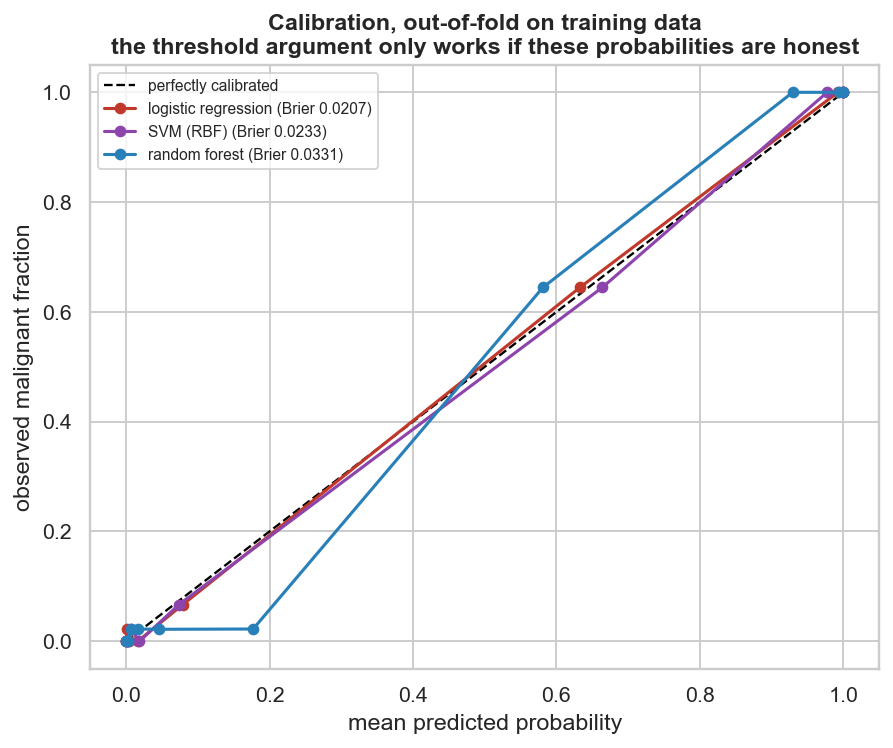

In [8]:
F.calibration(curves)
Image("../outputs/figures/08_calibration.png")

Logistic regression tracks the diagonal closely (Brier 0.021). The random forest
(0.033) visibly deviates — it is reluctant to predict probabilities near 0 or 1, because
its predictions are vote proportions across trees. Using it here would mean a threshold
of 0.14 did not correspond to a 14% risk, and the whole argument below would rest on
nothing. This is the concrete reason the calibration metric drove the model choice.

### The trade-off

Sweeping the threshold across the out-of-fold predictions, averaged over 20 repeats so
the chosen value is a property of the data rather than of one random split.

In [9]:
grid = np.round(np.arange(0.01, 0.71, 0.01), 3)
sweep = E.threshold_sweep(y_train, oof, grid)
targets = E.sensitivity_table(sweep, targets=(0.95, 0.97, 0.98, 0.99))
targets.round(4)

,target_recall,reachable,threshold,recall,specificity,precision,accuracy,false_neg,false_pos
0,0.95,True,0.50,0.9509,0.9851,0.9744,0.9723,8.35,4.25
1,0.97,True,0.31,0.9715,0.9679,0.9475,0.9692,4.85,9.15
2,0.98,True,0.14,0.9809,0.9318,0.8956,0.9501,3.25,19.45
3,0.99,True,0.06,0.9903,0.8547,0.8027,0.9054,1.65,41.40


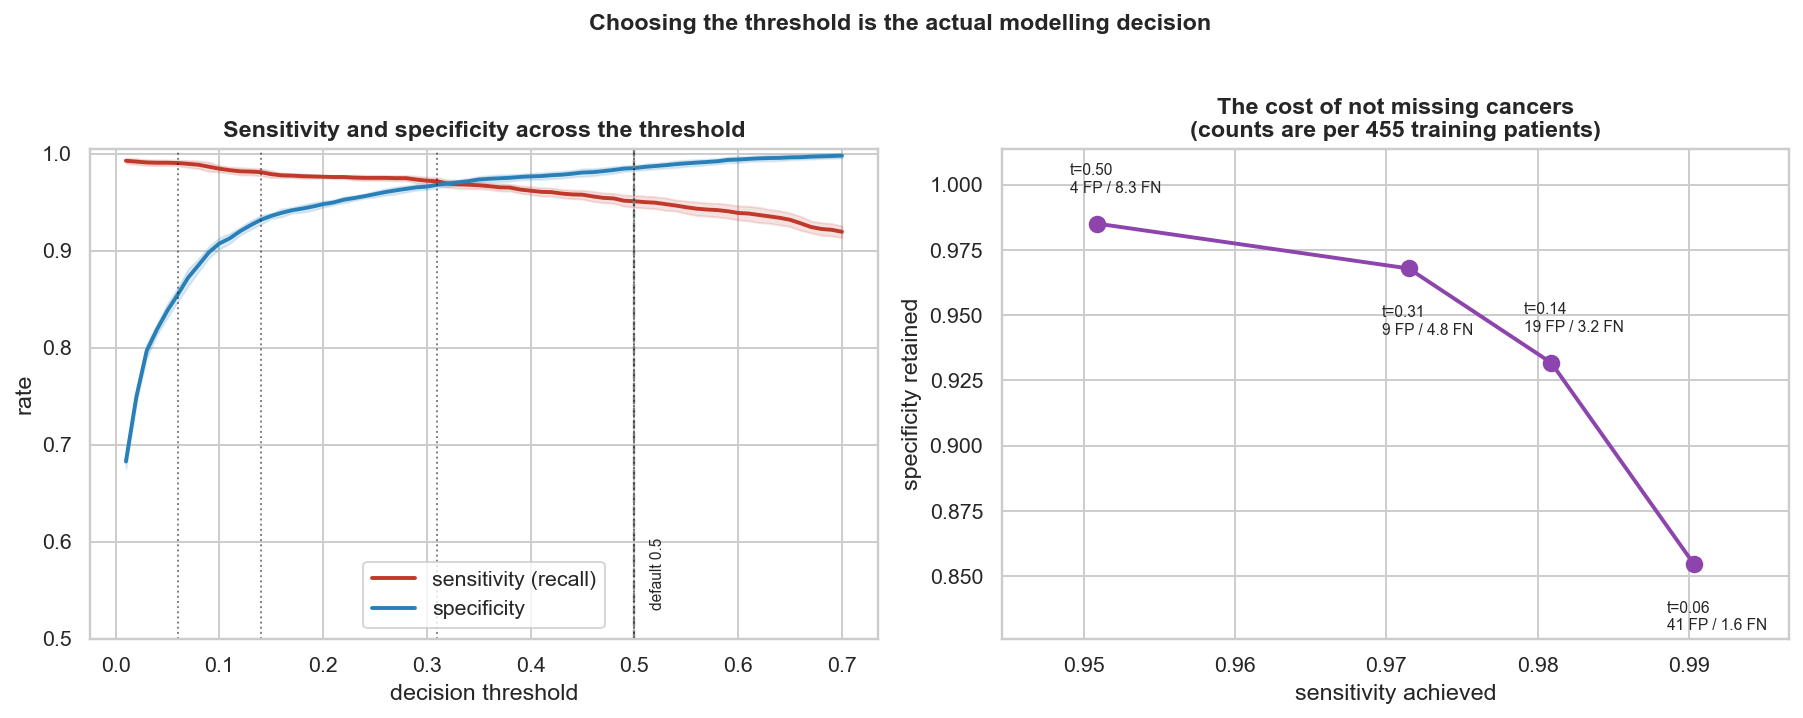

In [10]:
F.sensitivity_tradeoff(sweep, targets)
Image("../outputs/figures/09_sensitivity_tradeoff.png")

**This table is the result of the project.** Read across it:

| Sensitivity target | Threshold | Specificity | False negatives | False positives |
|---|---|---|---|---|
| 95% (the default gives this) | 0.50 | 98.5% | 8.4 | 4.3 |
| 97% | 0.31 | 96.8% | 4.9 | 9.2 |
| **98%** | **0.14** | **93.2%** | **3.3** | **19.5** |
| 99% | 0.06 | 85.5% | 1.7 | 41.4 |

(counts per 455 patients)

Moving from the default to 99% sensitivity **cuts missed cancers from 8.4 to 1.7 — a
fifth — and costs 13 points of specificity**, taking false positives from 4 to 41. Every
one of those extra 37 is a patient sent for an unnecessary biopsy.

Note also the shape: the curve is nearly flat from 0.5 down to 0.3 and then falls away
sharply. The first two percentage points of sensitivity are cheap; the last one is not.

**The choice made here is 98% sensitivity, threshold 0.14.** That is a judgement, not a
result. The reasoning: at 95% the model misses one cancer in twenty, which the default
delivers only by accident; 99% costs a further 13 points of specificity and nearly
doubles the biopsy rate again. 98% is where the curve turns. A clinician with real cost
data might reasonably choose differently — which is exactly why the whole curve is
reported rather than a single number, and why `TARGET_SENSITIVITY` is a named constant
in `run_analysis.py` rather than a magic value.

### The cases no threshold can save

In [11]:
malignant = y_train.to_numpy() == 1
never = (oof[:, malignant] < 0.05).all(axis=0)
print(f"malignant cases scored below 0.05 in ALL 20 repeats: {never.sum()} of {malignant.sum()}")

hardest = pd.DataFrame({
    "wdbc_id": D.load().loc[X_train.index[malignant], "id"].values,
    "mean_oof_probability": oof[:, malignant].mean(axis=0),
}).sort_values("mean_oof_probability").head(4)
print()
print(hardest.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

malignant cases scored below 0.05 in ALL 20 repeats: 1 of 170

  wdbc_id  mean_oof_probability
   892189                0.0018
881094802                0.0549
   855167                0.0876
   868202                0.1390


One malignant case (patient 892189) is scored at **0.0018** — the model is
confidently, consistently wrong about it across every fold shuffling. Its measurements
sit in the bottom 5th percentile of malignant cases on size and concavity: on these 30
features it simply looks benign.

No threshold rescues it. Reaching 100% sensitivity on this training set is impossible at
any cut above 0.005, where specificity has already collapsed to 60%. This bounds what
the feature set can do — catching that patient needs information that a nuclear
morphometry image does not contain.

---

## Held-out test set — evaluated once

Everything above used only the 455 training patients. The 114 held-out patients are now
scored once, at both thresholds.

In [12]:
final = M.final_model().fit(X_train, y_train)
test_probabilities = final.predict_proba(X_test)[:, 1]

operating_threshold = float(E.threshold_for_sensitivity(sweep, 0.98)["threshold"])
rows = []
for label, threshold in {"default": 0.5, "chosen (98% target)": operating_threshold}.items():
    summary = E.summarise(y_test, test_probabilities, threshold)
    low, high = E.wilson_interval(summary["tp"], summary["tp"] + summary["fn"])
    rows.append({"operating point": label, "threshold": threshold,
                 "sensitivity": summary["recall"], "sens. 95% CI": f"[{low:.3f}, {high:.3f}]",
                 "specificity": summary["specificity"], "precision": summary["precision"],
                 "accuracy": summary["accuracy"], "missed cancers": summary["fn"],
                 "false alarms": summary["fp"]})
print(f"ROC AUC {summary['roc_auc']:.4f} | average precision {summary['average_precision']:.4f} "
      f"| Brier {summary['brier']:.4f}\n")
pd.DataFrame(rows).round(4)

ROC AUC 0.9960 | average precision 0.9943 | Brier 0.0213



,operating point,threshold,sensitivity,sens. 95% CI,specificity,precision,accuracy,missed cancers,false alarms
0,default,0.50,0.9286,"[0.810, 0.975]",0.9861,0.9750,0.9649,3,1
1,chosen (98% target),0.14,0.9762,"[0.877, 0.996]",0.9444,0.9111,0.9561,1,4


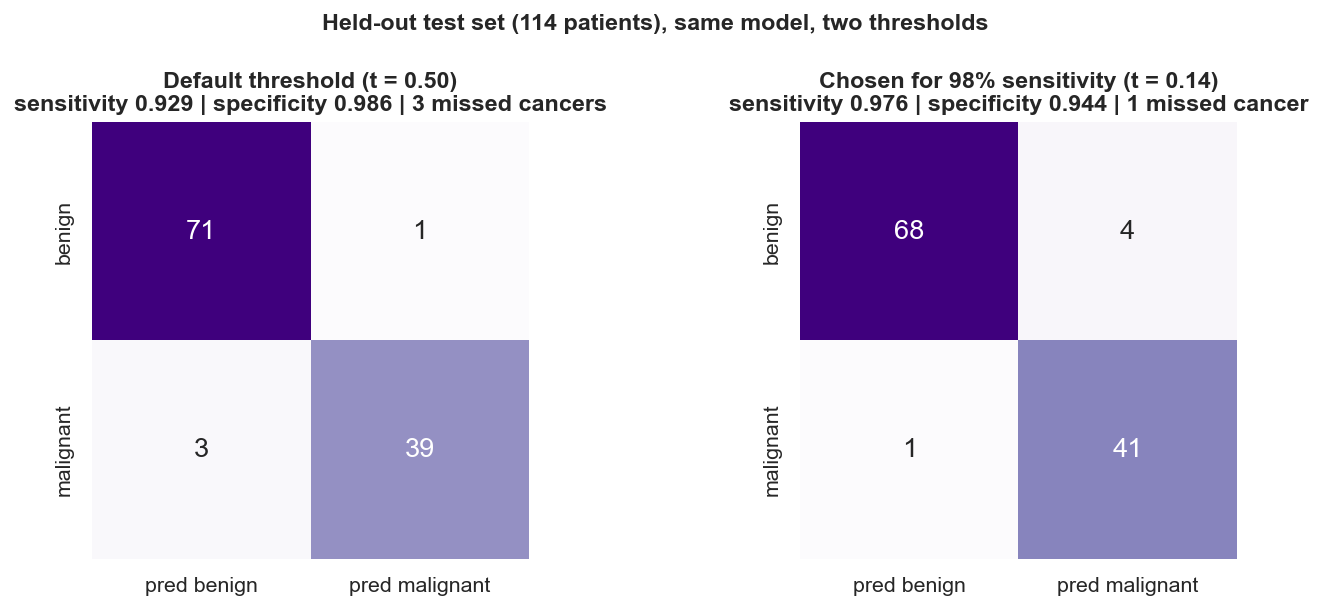

In [13]:
F.confusion_at_thresholds(y_test, test_probabilities,
                          {"Default threshold": 0.5,
                           "Chosen for 98% sensitivity": operating_threshold})
Image("../outputs/figures/11_confusion_matrices.png")

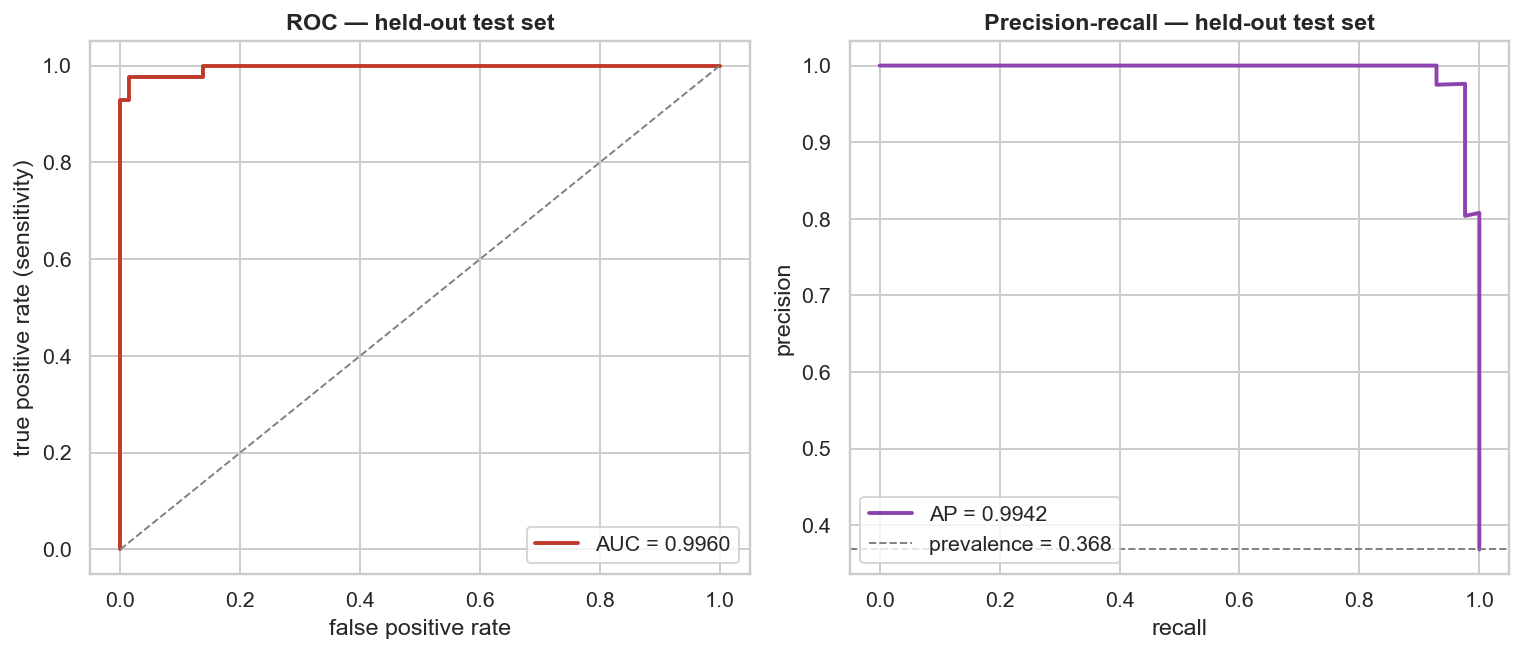

In [14]:
F.roc_and_pr(y_test, test_probabilities)
Image("../outputs/figures/07_roc_and_pr.png")

### What happened

| | Default (0.50) | Chosen (0.14) |
|---|---|---|
| Sensitivity | 92.9% | **97.6%** |
| Specificity | 98.6% | 94.4% |
| **Accuracy** | **96.5%** | **95.6%** |
| **Missed cancers** | **3 of 42** | **1 of 42** |
| False alarms | 1 | 4 |

**The threshold chosen on training data transferred**: it targeted 98% sensitivity and
delivered 97.6% on patients the model had never seen.

And here is the point of the whole project. By the metric almost every version of this
dataset reports, the chosen model is **worse** — accuracy falls from 96.5% to 95.6%. By
the metric that matters clinically, it **misses two thirds fewer cancers**: three
undiagnosed patients become one, at a cost of three extra biopsies.

Reporting the 96.5% and stopping would not be wrong arithmetic. It would be answering a
question nobody asked.

## Limitations

Stated plainly, because a model in this domain that does not state them is not
trustworthy.

**This is not a clinical tool and could not become one.** It classifies pre-extracted
morphometric features, not images. It has no regulatory validation and no prospective
evaluation. The label is a diagnosis already made by a pathologist — the model is
learning to reproduce expert judgement on curated data, not to replace it.

**The sample is small and old.** 569 patients from one institution in the early 1990s.
Imaging equipment, staining protocols, and the referred population have all changed. The
114-patient test set is the binding constraint on every number here: one patient is 0.9
percentage points, and the 95% CI on the headline sensitivity is [0.877, 0.996]. A
point estimate quoted to four decimals from 42 malignant cases would be false precision,
which is why the interval is reported alongside it.

**Selection bias is unquantifiable here.** These are masses that were biopsied — already
suspicious enough for a clinician to act. The 37% malignancy rate is a property of that
referral filter, not of the population, so the precision figures do not transfer to a
screening setting where prevalence is far lower. At lower prevalence the same
sensitivity and specificity would produce far more false positives per true one.

**The 13 zero-concavity cases are a small-sample risk.** All benign, and the model can
lean on that harder than 13 patients justify. It is the kind of rule most likely to
break on a new cohort.

**Coefficients are associations, not mechanisms.** With 23 of 30 features above VIF 10,
weight moves freely between collinear columns. The coefficient plot below shows what the
model uses, not what causes malignancy.

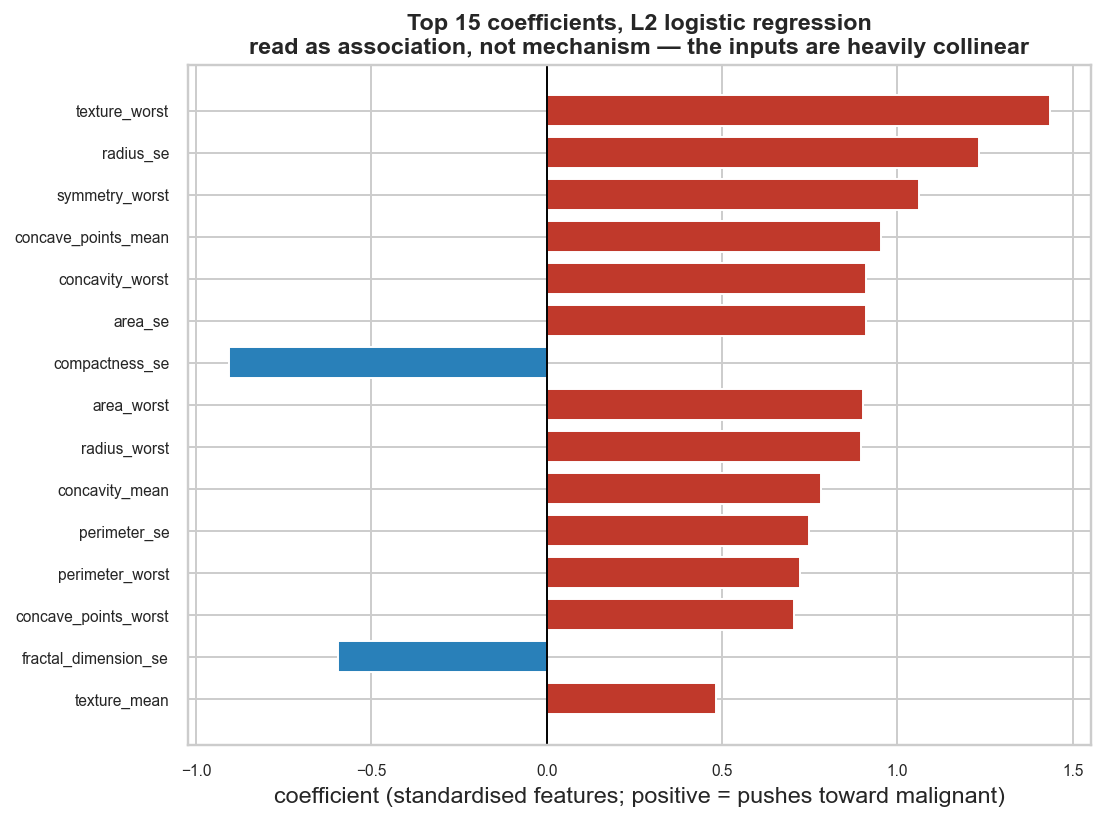

In [15]:
F.coefficients(final, features)
Image("../outputs/figures/10_coefficients.png")

## Summary

1. **Model choice is not the lever.** Nine classifiers land within a fifth of a standard
   deviation of each other; tuning `C` moves AUC by 0.00008.
2. **Two thirds of the features are redundant.** The 10 "worst" measurements match all
   30; the 1993 authors' 3 features get within 1.5 points.
3. **The threshold is the real decision.** Moving from 0.50 to 0.14 trades 0.9 points of
   accuracy for a two-thirds reduction in missed cancers — and it held up out of sample.
4. **Some errors are irreducible.** One malignant case is scored 0.002 by every model in
   every fold. 100% sensitivity is not available at any threshold worth using.